# Насколько отличаются длины реальных и синтетических объявлений

Сравнение public до/после удаления нормализованных повторов, готовой реальной
обучающей части и синтетического Avito v2. Здесь используются сохранённые
`stats.json`: notebook не обучает модели, не меняет данные и не требует весов.

**Основной вывод:** разница длин сохраняется после удаления повторов. В v2 нет
объявлений от 1 000 символов, тогда как они составляют большую часть реальных.
Это различие распределений, а не доказанная причина изменения F1.

Слова ниже — последовательности букв, **не токены LLM**. Символы включают
пробелы и переводы строк. Физические строки включают внутренние пустые строки.
Готовые PNG и SVG экспортируются рядом с notebook.

In [1]:
import json
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Image, Markdown

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'avito_compare').is_dir() and (p / 'output').is_dir()), None)
if root is None:
    raise RuntimeError('Open this notebook inside the repository (avito_compare + output).')
folder = root / 'output' / 'dataset-length-comparison'
stats = json.loads((folder / 'stats.json').read_text(encoding='utf-8'))

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 14,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'svg.fonttype': 'none',
})
COLORS = {'public': '#2563EB', 'synthetic': '#DB6B27', 'raw': '#64748B'}

def export_figure(fig, stem):
    fig.savefig(folder / (stem + '.png'), dpi=220, bbox_inches='tight')
    fig.savefig(folder / (stem + '.svg'), bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(folder / (stem + '.png'))))

print('Data source: saved stats.json; no training or data mutation.')
print('Matplotlib:', matplotlib.__version__)
print('Source files unchanged during original analysis:', stats['checks']['all_source_hashes_unchanged'])

Data source: saved stats.json; no training or data mutation.
Matplotlib: 3.11.2
Source files unchanged during original analysis: True


## Числа, которые определяют масштаб разницы

Public raw содержит повторяющиеся объявления; public deduplicated оставляет
первую версию каждого текста после `casefold` и свёртки пробелов. Готовые
public train/calibration/test содержат тот же набор нормализованных текстов.
Поэтому дедуплицированный public — более честное сравнение разнообразия.

In [2]:
labels = [
    ('Public raw', 'public_raw'),
    ('Public deduplicated', 'public_dedup_normalized'),
    ('Actual public train', 'public_prepared_train'),
    ('V2 train', 'v2_train'),
    ('V2 test', 'v2_test'),
]
table = ['| Набор | Строк | Медиана символов | p95 символов | Max | Медиана слов | Медиана строк |',
         '|---|---:|---:|---:|---:|---:|---:|']
for label, key in labels:
    s = stats[key]
    table.append(f"| {label} | {s['rows']:,} | {s['characters']['median']:,.0f} | {s['characters']['p95']:,.0f} | {s['characters']['max']:,.0f} | {s['words']['median']:,.0f} | {s['lines']['median']:,.0f} |")
display(Markdown('\n'.join(table)))
ratio = stats['public_dedup_normalized']['characters']['median'] / stats['v2_train']['characters']['median']
display(Markdown(f'Медианный дедуплицированный public-текст длиннее медианного v2 train в **{ratio:.2f} раза**.'))

| Набор | Строк | Медиана символов | p95 символов | Max | Медиана слов | Медиана строк |
|---|---:|---:|---:|---:|---:|---:|
| Public raw | 10,000 | 2,196 | 4,960 | 5,564 | 285 | 46 |
| Public deduplicated | 4,855 | 1,467 | 4,952 | 5,564 | 185 | 38 |
| Actual public train | 3,398 | 1,465 | 4,953 | 5,536 | 184 | 38 |
| V2 train | 8,464 | 143 | 409 | 530 | 19 | 1 |
| V2 test | 3,016 | 155 | 415 | 433 | 21 | 1 |

Медианный дедуплицированный public-текст длиннее медианного v2 train в **10.26 раза**.

## 1. Профиль распределения длин

График построен по сохранённым перцентилям, это **не восстановленная точная
гистограмма или CDF**. Логарифмическая шкала помогает видеть и короткие, и длинные
описания. Raw public показан отдельно, чтобы видеть влияние повторов.

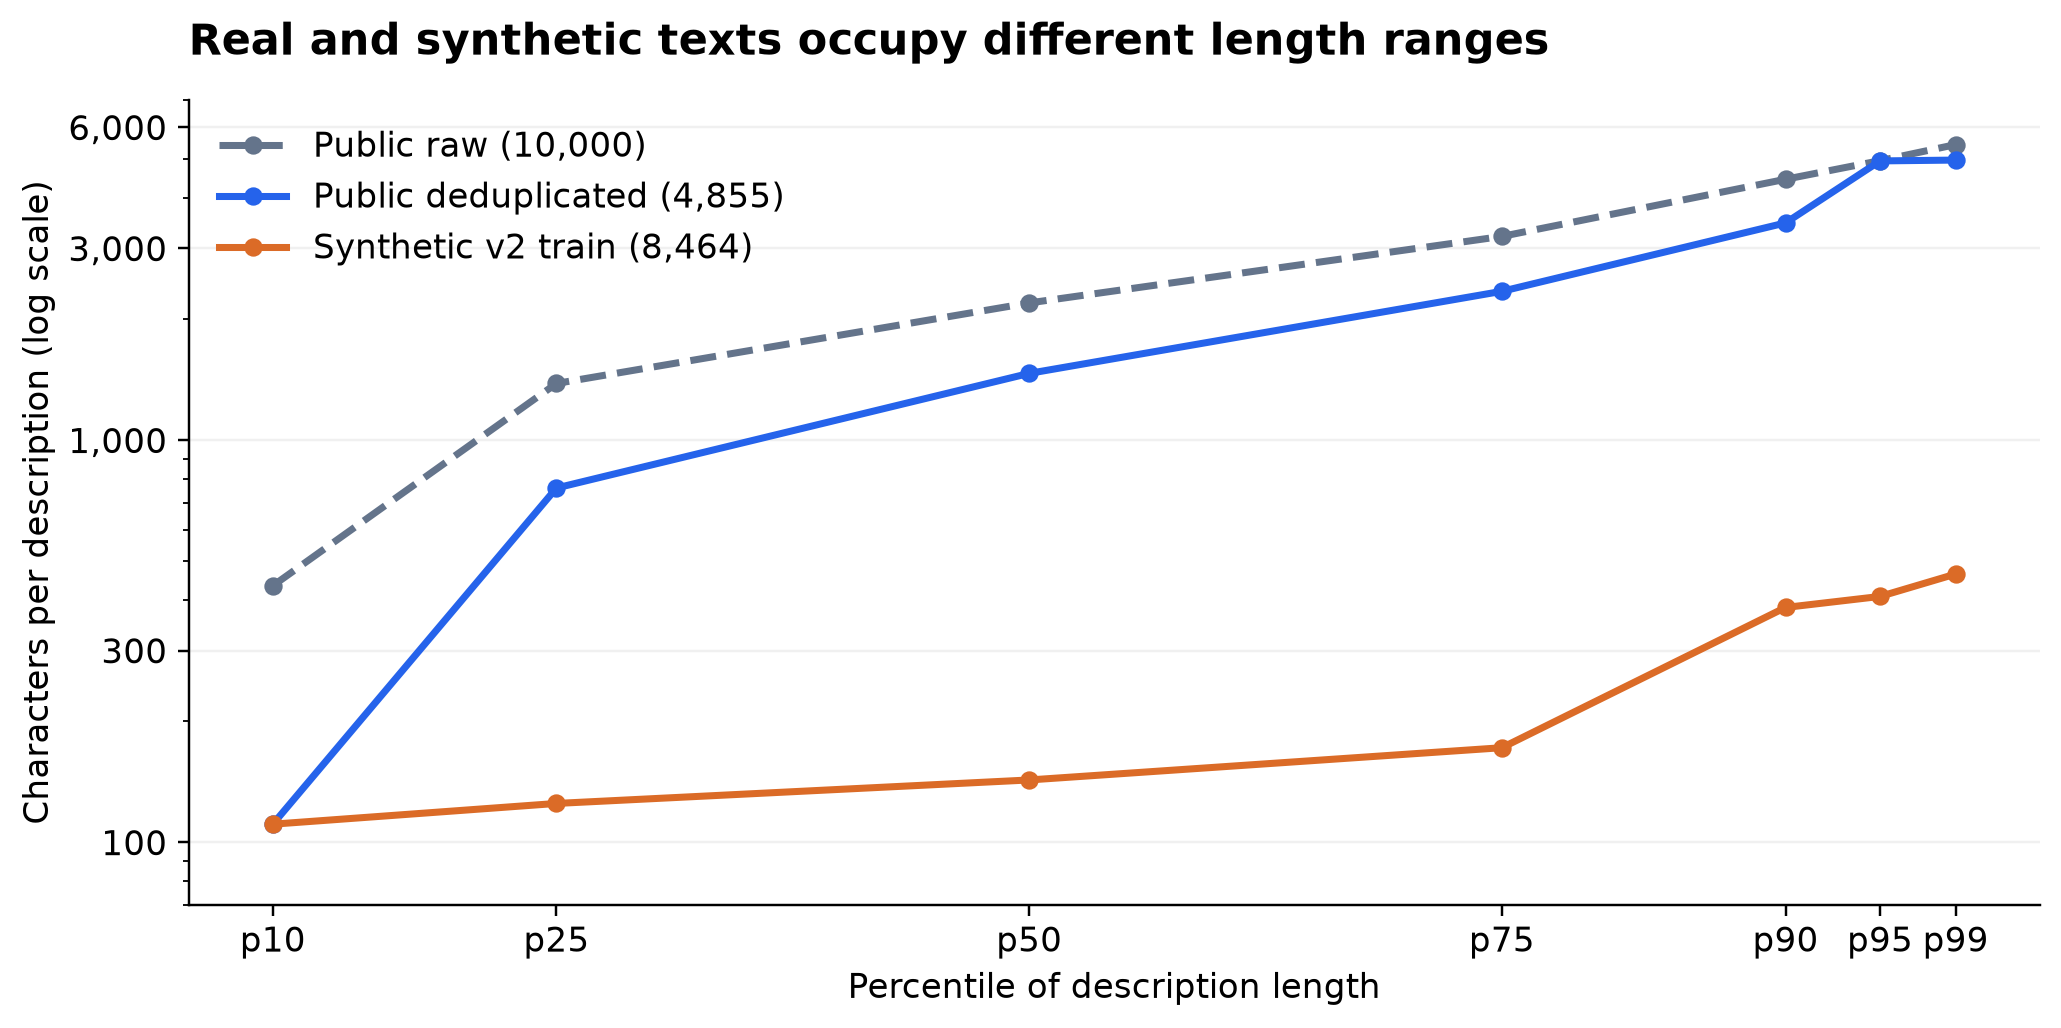

In [3]:
percentiles = ['p10', 'p25', 'median', 'p75', 'p90', 'p95', 'p99']
positions = [10, 25, 50, 75, 90, 95, 99]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for key, label, color, style in [
    ('public_raw', 'Public raw (10,000)', COLORS['raw'], '--'),
    ('public_dedup_normalized', 'Public deduplicated (4,855)', COLORS['public'], '-'),
    ('v2_train', 'Synthetic v2 train (8,464)', COLORS['synthetic'], '-'),
]:
    ax.plot(positions, [stats[key]['characters'][p] for p in percentiles],
            marker='o', linewidth=2.3, markersize=5, color=color, linestyle=style, label=label)
ax.set_yscale('log')
ax.set_xticks(positions, ['p10', 'p25', 'p50', 'p75', 'p90', 'p95', 'p99'])
ax.set_yticks([100, 300, 1000, 3000, 6000], ['100', '300', '1,000', '3,000', '6,000'])
ax.set_ylim(70, 7000)
ax.set_xlabel('Percentile of description length')
ax.set_ylabel('Characters per description (log scale)')
ax.set_title('Real and synthetic texts occupy different length ranges', loc='left', pad=15)
ax.grid(axis='y', which='major', alpha=.18)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
export_figure(fig, '01_length_quantiles')

## 2. Доли коротких и длинных текстов

Интервалы отражают точные доли из полного анализа, а не выборку. В v2 train
все тексты короче 600 символов. В public после удаления повторов около 70%
описаний имеют от 1 000 символов.

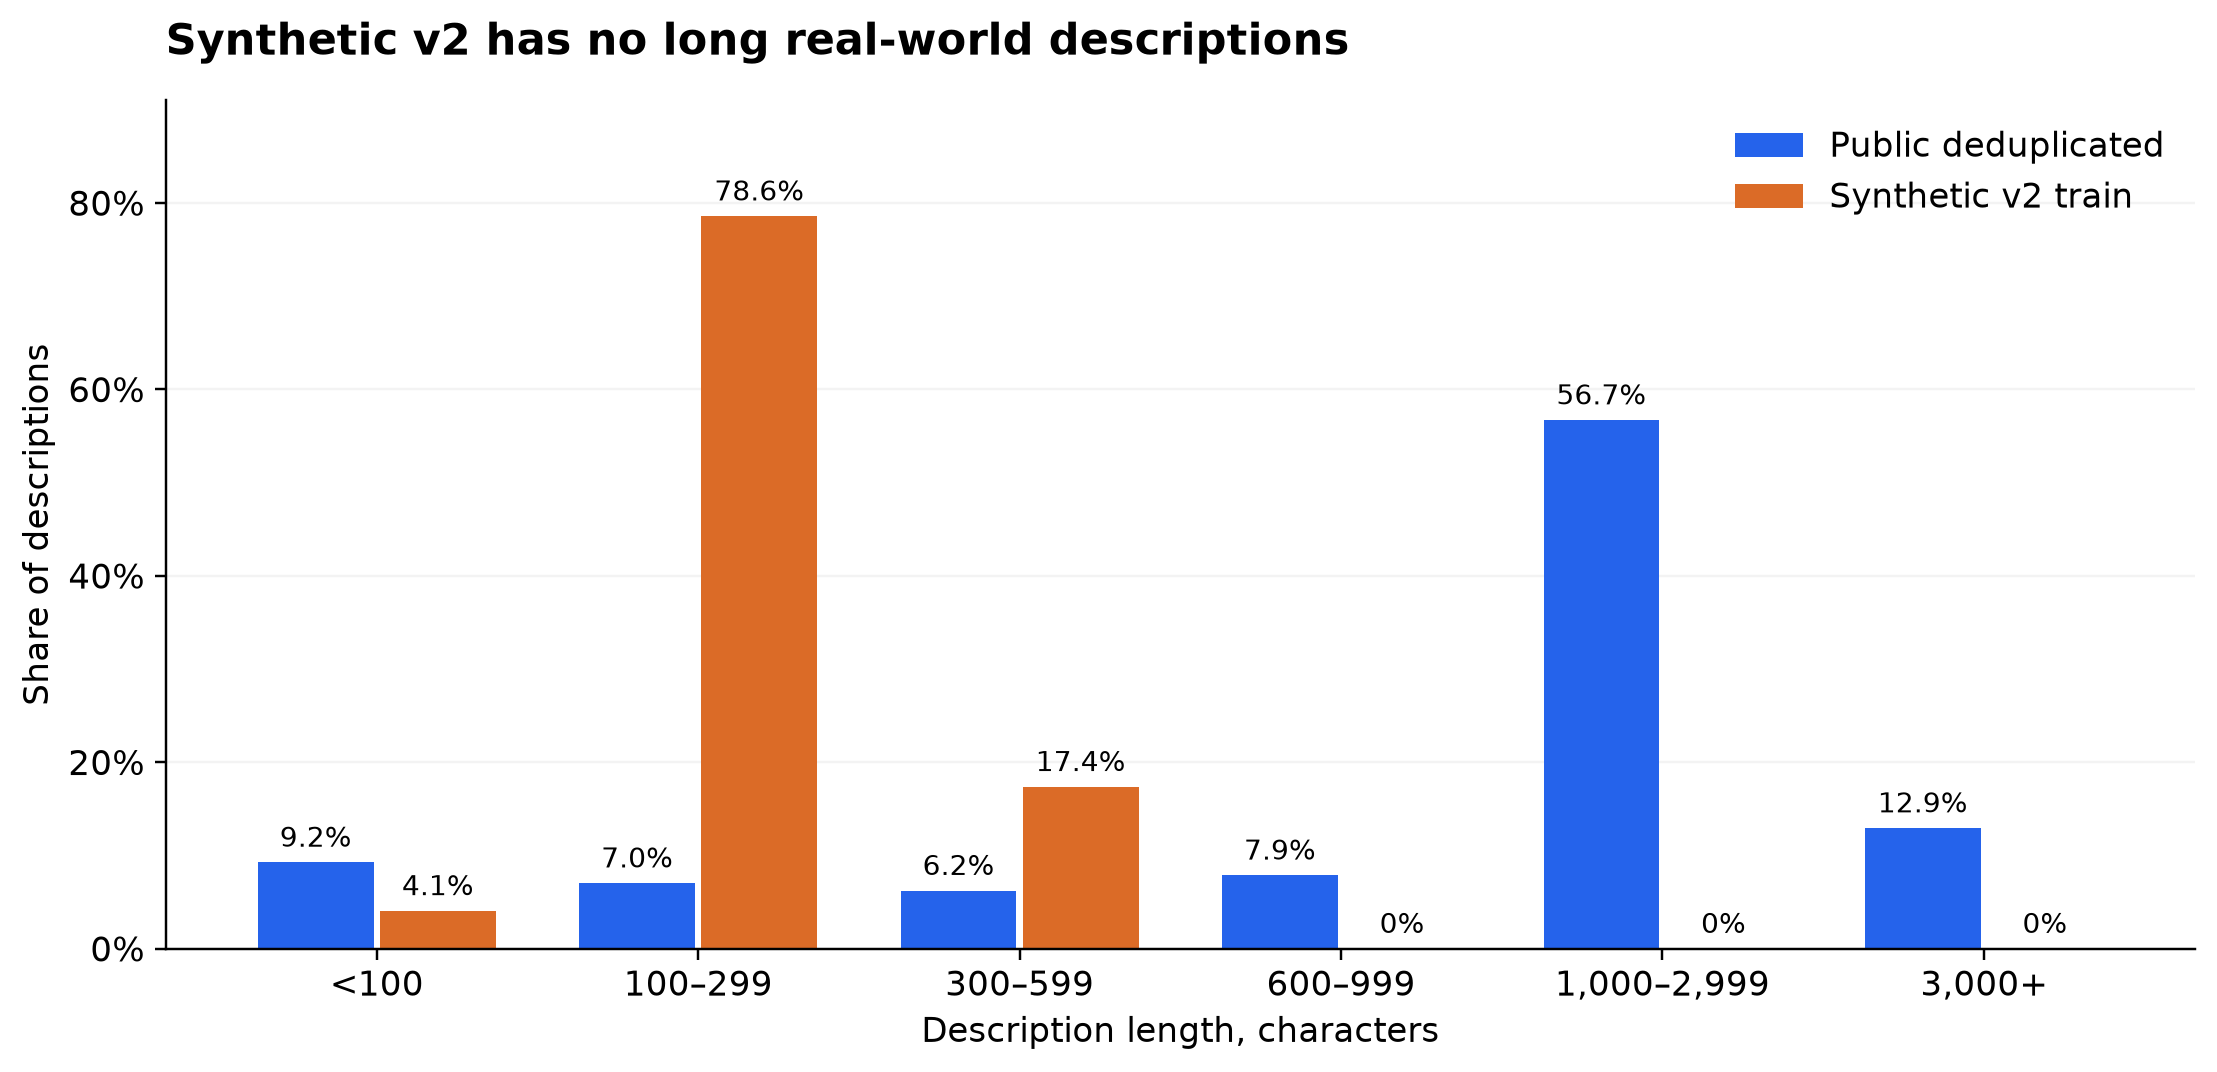

In [4]:
buckets = ['<100', '100-299', '300-599', '600-999', '1000-2999', '3000+']
x = list(range(len(buckets)))
fig, ax = plt.subplots(figsize=(10.2, 5))
for offset, key, label, color in [
    (-.19, 'public_dedup_normalized', 'Public deduplicated', COLORS['public']),
    (.19, 'v2_train', 'Synthetic v2 train', COLORS['synthetic']),
]:
    heights = [stats[key]['character_bucket_percent'][b] for b in buckets]
    bars = ax.bar([i + offset for i in x], heights, width=.36, color=color, label=label)
    ax.bar_label(bars, labels=[f'{v:.1f}%' if v else '0%' for v in heights], fontsize=9, padding=3)
ax.set_xticks(x, ['<100', '100–299', '300–599', '600–999', '1,000–2,999', '3,000+'])
ax.set_ylim(0, 91)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_ylabel('Share of descriptions')
ax.set_xlabel('Description length, characters')
ax.set_title('Synthetic v2 has no long real-world descriptions', loc='left', pad=15)
ax.grid(axis='y', alpha=.15)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
export_figure(fig, '02_length_buckets')

## 3. Смешанный train: документы и символы дают разную картину

Сравниваем фактическую смесь 3 398 public + 8 464 v2. IDF зависит от количества
**документов** с признаком, а не от суммы символов. Поэтому короткая синтетика
может сильно изменить статистику IDF, хотя большинство букв в смеси остаётся
в реальных объявлениях. Ни сумма символов, ни её доля не являются прямым весом
документов в SGD.

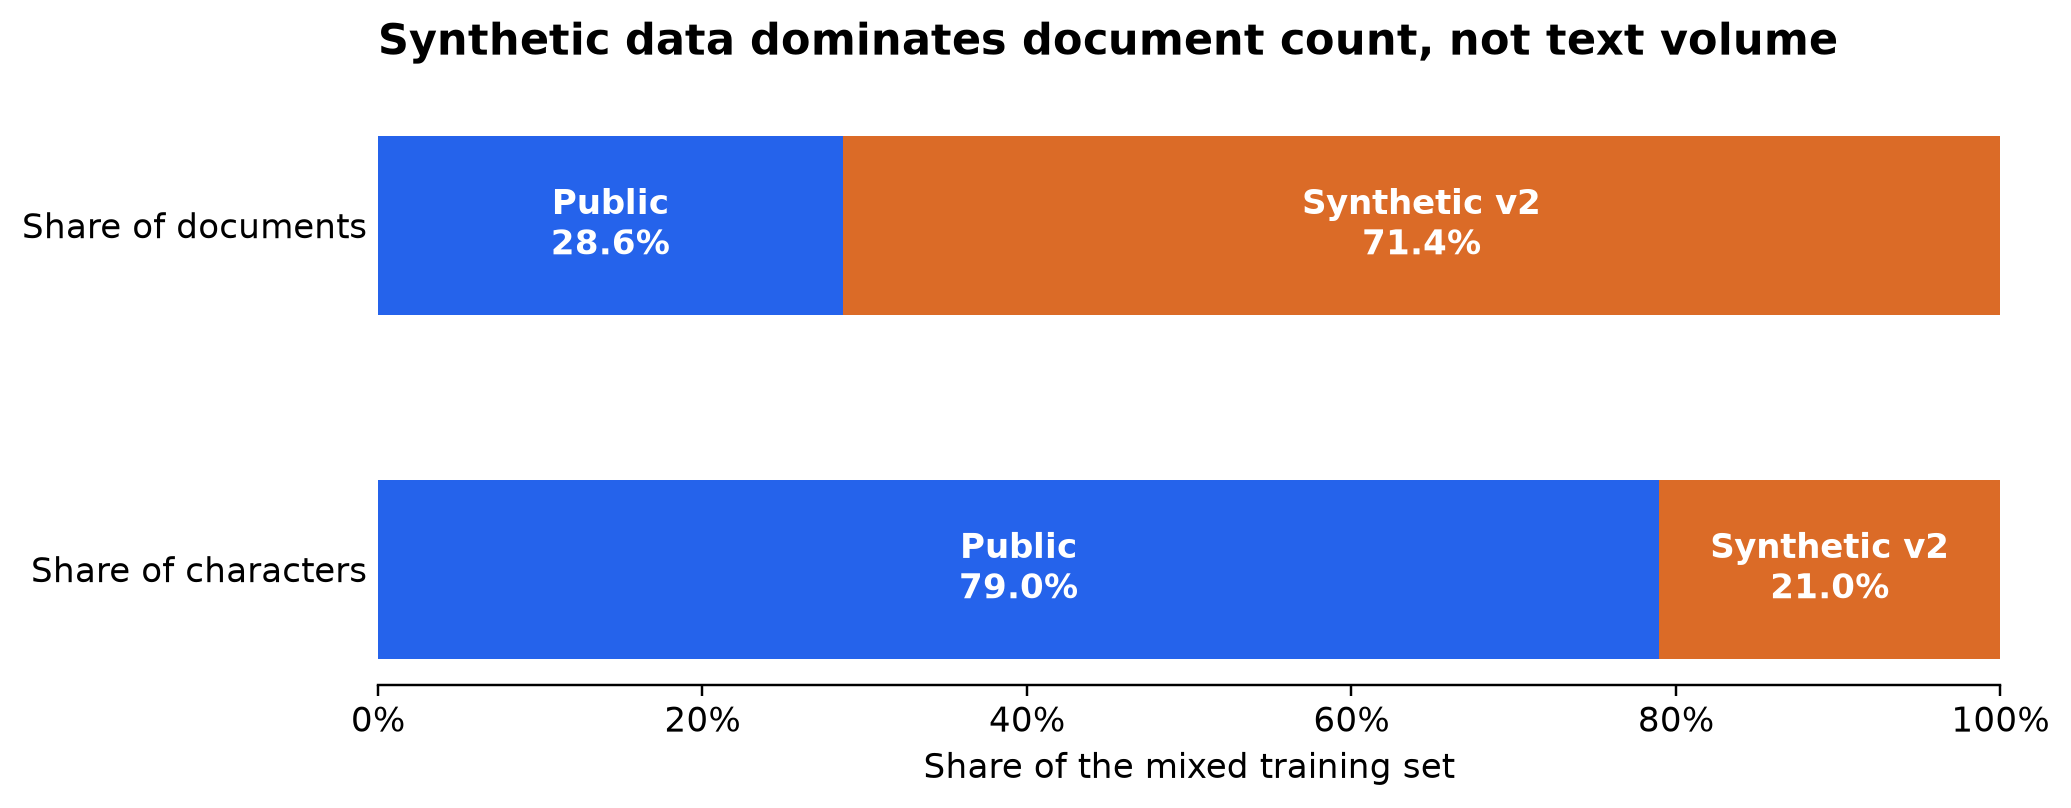

Public: 3398 documents; 5,814,691 characters
V2: 8464 documents; 1,548,996 characters


In [5]:
mix = stats['mixed_train_composition']
fig, ax = plt.subplots(figsize=(9.5, 3.8))
metrics = [('row_share_percent', 'Share of documents'),
           ('character_share_percent', 'Share of characters')]
for y, (metric, label) in enumerate(metrics):
    start = 0
    for name, text, color in [('public', 'Public', COLORS['public']),
                              ('v2', 'Synthetic v2', COLORS['synthetic'])]:
        value = mix[name][metric]
        ax.barh(y, value, left=start, height=.52, color=color,
                label=text if y == 0 else None)
        ax.text(start + value / 2, y, f'{text}\n{value:.1f}%',
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
        start += value
ax.set_yticks([0, 1], [label for _, label in metrics])
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.invert_yaxis()
ax.set_title('Synthetic data dominates document count, not text volume', loc='left', pad=18)
ax.set_xlabel('Share of the mixed training set')
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0)
fig.tight_layout()
export_figure(fig, '03_mixed_composition')

print('Public:', mix['public']['rows'], 'documents;', f"{mix['public']['characters']:,}", 'characters')
print('V2:', mix['v2']['rows'], 'documents;', f"{mix['v2']['characters']:,}", 'characters')

## Что можно и нельзя заключить

- **Измерено:** даже после дедупликации медианы отличаются примерно в десять раз;
  длина и структура v2 не покрывают большую часть длинных реальных объявлений.
- **Измерено:** в смеси синтетика составляет 71,35% документов, но 21,04% символов.
- **Гипотезы для проверки:** изменение IDF и конкуренции за `max_features`,
  другой контекст услуг/отрицаний, влияние L2-нормализации вектора.
- **Не доказано:** что именно длина является причиной изменения F1. Одновременно
  меняются лексика, шаблоны, содержание и доля искусственных отрицаний.
- Следует отдельно показывать метрики реального и синтетического test, а долю
  или вес синтетики подбирать по реальной validation. Нельзя автоматически
  обрезать реальные тексты до размера v2 или растягивать v2 без проверки смысла.

Полные перцентили, интервалы и контрольные суммы: `stats.json`.
Текстовый отчёт: `report.md`. Полный пересчёт длин: `compare_lengths.py`.
Воспроизведение этого notebook и графиков: `build_notebook.py`.
Новые обучения в этом анализе не запускались.